In [2]:
import xarray as xr

ds = xr.open_dataset("data.grib", engine="cfgrib")
print(ds)

skipping variable: paramId==228 shortName='tp'
Traceback (most recent call last):
  File "/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/cfgrib/dataset.py", line 726, in build_dataset_components
    dict_merge(variables, coord_vars)
    ~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^
  File "/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/cfgrib/dataset.py", line 642, in dict_merge
    raise DatasetBuildError(
    ...<2 lines>...
    )
cfgrib.dataset.DatasetBuildError: key present and new value is different: key='time' value=Variable(dimensions=('time',), data=array([1588291200, 1588294800, 1588298400, ..., 1786464000, 1786467600,
       1786471200], shape=(20179,))) new_value=Variable(dimensions=('time',), data=array([1588269600, 1588312800, 1588356000, ..., 1786341600, 1786384800,
       1786428000], shape=(1688,)))


<xarray.Dataset> Size: 633MB
Dimensions:              (time: 20179, latitude: 37, longitude: 53)
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Data variables:
    t2m                  (time, latitude, longitude) float32 158MB ...
    msl                  (time, latitude, longitude) float32 158MB ...
    sst                  (time, latitude, longitude) float32 158MB ...
    swvl1                (time, latitude, longitude) float32 158MB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for M

In [3]:
print(ds['t2m'])
print(ds['t2m'].values.min(), ds['t2m'].values.max())

<xarray.DataArray 't2m' (time: 20179, latitude: 37, longitude: 53)> Size: 158MB
[39571019 values with dtype=float32]
Coordinates:
  * time                 (time) datetime64[ns] 161kB 2020-05-01 ... 2026-08-1...
    valid_time           (time) datetime64[ns] 161kB ...
  * latitude             (latitude) float64 296B 51.0 50.75 50.5 ... 42.25 42.0
  * longitude            (longitude) float64 424B -5.0 -4.75 -4.5 ... 7.75 8.0
    number               int64 8B ...
    step                 timedelta64[ns] 8B ...
    surface              float64 8B ...
    depthBelowLandLayer  float64 8B ...
Attributes: (12/31)
    GRIB_paramId:                             167
    GRIB_dataType:                            an
    GRIB_numberOfPoints:                      1961
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    ...                                       ...
    GRIB_shortName:            

In [4]:
# Convert to Celsius
ds['t2m_celsius'] = ds['t2m'] - 273.15

# Confirm the conversion looks right
print(ds['t2m_celsius'].values.min(), ds['t2m_celsius'].values.max())

-9.256683 43.58609


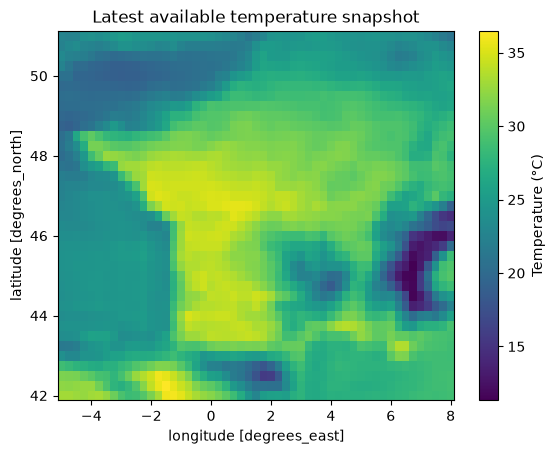

In [5]:
import matplotlib.pyplot as plt

ds['t2m_celsius'].isel(time=-1).plot()
plt.title("Latest available temperature snapshot")
plt.gca().collections[0].colorbar.set_label("Temperature (°C)")
plt.show()

In [6]:
import pandas as pd

# Extract data for Paris (lat 48.85, lon 2.35)
df = ds['t2m_celsius'].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()

# Get daily max temperature
df['date'] = pd.to_datetime(df['time']).dt.date
daily_max = df.groupby('date')['t2m_celsius'].max().reset_index()
daily_max['date'] = pd.to_datetime(daily_max['date'])
daily_max['day_of_year'] = daily_max['date'].dt.dayofyear

print(daily_max.head())
print(daily_max.shape)

        date  t2m_celsius  day_of_year
0 2020-05-01    15.580231          122
1 2020-05-02    16.307037          123
2 2020-05-03    19.640289          124
3 2020-05-04    18.876617          125
4 2020-05-05    14.094635          126
(841, 3)


In [7]:
# Compute the 90th percentile threshold per calendar day (using all years)
threshold = daily_max.groupby('day_of_year')['t2m_celsius'].transform(lambda x: x.quantile(0.90))
daily_max['is_hot_day'] = daily_max['t2m_celsius'] > threshold

# Check that consecutive rows are actually consecutive calendar days
daily_max = daily_max.sort_values('date').reset_index(drop=True)
daily_max['day_gap'] = daily_max['date'].diff().dt.days

# A new "streak" starts whenever: the hot/not-hot flag changes, OR there's a gap in dates
daily_max['new_streak'] = (daily_max['is_hot_day'] != daily_max['is_hot_day'].shift()) | (daily_max['day_gap'] != 1)
daily_max['streak_id'] = daily_max['new_streak'].cumsum()

# Flag heat wave: 3+ consecutive hot days (with no date gaps)
streak_lengths = daily_max[daily_max['is_hot_day']].groupby('streak_id').size()
valid_streaks = streak_lengths[streak_lengths >= 3].index
daily_max['is_heatwave'] = daily_max['streak_id'].isin(valid_streaks) & daily_max['is_hot_day']

# Check results
print(daily_max['is_heatwave'].sum(), "heatwave days found out of", len(daily_max), "total days")
print(daily_max[daily_max['is_heatwave']].head(10))

75 heatwave days found out of 841 total days
          date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
96  2020-08-05    29.897125          218        True      1.0        True   
97  2020-08-06    33.529449          219        True      1.0       False   
98  2020-08-07    35.633453          220        True      1.0       False   
99  2020-08-08    36.358307          221        True      1.0       False   
100 2020-08-09    37.223053          222        True      1.0       False   
251 2022-05-06    21.255035          126        True      1.0        True   
252 2022-05-07    20.384430          127        True      1.0       False   
253 2022-05-08    21.489655          128        True      1.0       False   
260 2022-05-15    28.401276          135        True      1.0        True   
261 2022-05-16    24.868317          136        True      1.0       False   

     streak_id  is_heatwave  
96           8         True  
97           8         True  
98           8   

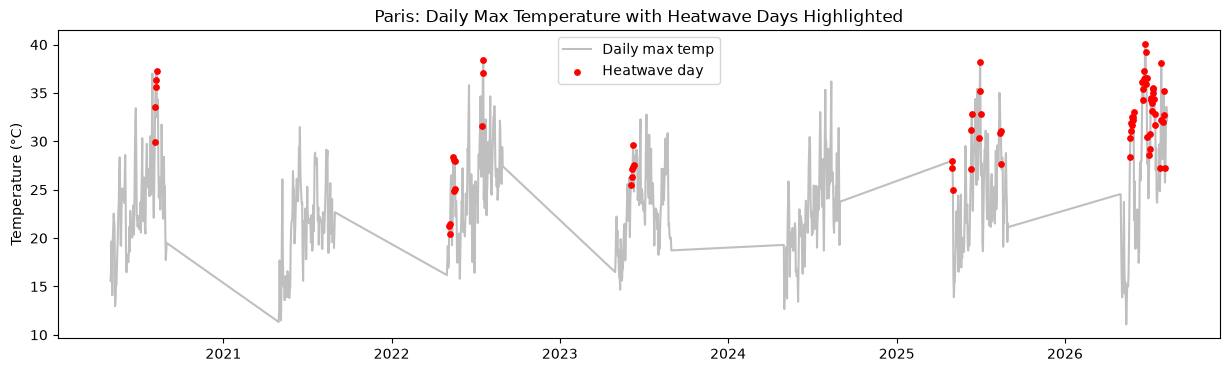

In [8]:
plt.figure(figsize=(15, 4))
plt.plot(daily_max['date'], daily_max['t2m_celsius'], color='gray', alpha=0.5, label='Daily max temp')
heatwave_days = daily_max[daily_max['is_heatwave']]
plt.scatter(heatwave_days['date'], heatwave_days['t2m_celsius'], color='red', s=15, label='Heatwave day', zorder=5)
plt.legend()
plt.title("Paris: Daily Max Temperature with Heatwave Days Highlighted")
plt.ylabel("Temperature (°C)")
plt.show()

2026 stands out clearly — noticeably more red dots and higher peaks (nearly 40°C) than any prior year, which lines up perfectly with everything we discussed earlier about this year's unusually intense, repeated heat wave season in Europe. This is a great sign your model's target variable is capturing something real, not noise.

The diagonal gray lines between seasons (e.g., late 2020 into early 2021) are just a plotting artifact — since you only pulled summer-season data, matplotlib is drawing a straight line connecting the last point of one season to the first point of the next, rather than leaving a gap. It's not a data problem, just a cosmetic thing. Not worth fixing right now, but if you want a cleaner plot later, you can insert NaN rows between seasons to break the line.

In [9]:
# Rolling/lagged temperature features
daily_max['temp_3day_avg'] = daily_max['t2m_celsius'].rolling(3).mean()
daily_max['temp_7day_avg'] = daily_max['t2m_celsius'].rolling(7).mean()
daily_max['temp_lag1'] = daily_max['t2m_celsius'].shift(1)
daily_max['temp_lag2'] = daily_max['t2m_celsius'].shift(2)

print(daily_max.head(10))

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  
0          1        False            NaN            NaN        NaN        NaN  
1          1  

In [10]:
# Extract the other variables for the same Paris location
extra_vars = ds[['msl', 'sst', 'swvl1']].sel(latitude=48.85, longitude=2.35, method="nearest").to_dataframe().reset_index()
extra_vars['date'] = pd.to_datetime(extra_vars['time']).dt.date

# Get daily mean for each (pressure/soil moisture don't need "max" like temperature does)
daily_extra = extra_vars.groupby('date')[['msl', 'sst', 'swvl1']].mean().reset_index()
daily_extra['date'] = pd.to_datetime(daily_extra['date'])

# Merge into your main daily_max dataframe
daily_max = daily_max.merge(daily_extra, on='date', how='left')

print(daily_max.head(10))
print(daily_max.isnull().sum())

        date  t2m_celsius  day_of_year  is_hot_day  day_gap  new_streak  \
0 2020-05-01    15.580231          122       False      NaN        True   
1 2020-05-02    16.307037          123       False      1.0       False   
2 2020-05-03    19.640289          124       False      1.0       False   
3 2020-05-04    18.876617          125       False      1.0       False   
4 2020-05-05    14.094635          126       False      1.0       False   
5 2020-05-06    19.743805          127       False      1.0       False   
6 2020-05-07    20.993073          128       False      1.0       False   
7 2020-05-08    22.520416          129       False      1.0       False   
8 2020-05-09    21.797516          130       False      1.0       False   
9 2020-05-10    21.279694          131       False      1.0       False   

   streak_id  is_heatwave  temp_3day_avg  temp_7day_avg  temp_lag1  temp_lag2  \
0          1        False            NaN            NaN        NaN        NaN   
1          1

In [11]:
daily_max = daily_max.drop(columns=['sst'])
print(daily_max.columns.tolist())
print(daily_max.isnull().sum())

['date', 't2m_celsius', 'day_of_year', 'is_hot_day', 'day_gap', 'new_streak', 'streak_id', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
date             0
t2m_celsius      0
day_of_year      0
is_hot_day       0
day_gap          1
new_streak       0
streak_id        0
is_heatwave      0
temp_3day_avg    2
temp_7day_avg    6
temp_lag1        1
temp_lag2        2
msl              0
swvl1            0
dtype: int64


In [12]:
# Drop rows with any missing values (mostly from the start of each season)
daily_max = daily_max.dropna().reset_index(drop=True)

# Drop helper columns no longer needed
daily_max = daily_max.drop(columns=['day_gap', 'new_streak', 'streak_id', 'is_hot_day'])

print(daily_max.shape)
print(daily_max.columns.tolist())
print(daily_max.head())

(835, 10)
['date', 't2m_celsius', 'day_of_year', 'is_heatwave', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
        date  t2m_celsius  day_of_year  is_heatwave  temp_3day_avg  \
0 2020-05-07    20.993073          128        False      18.277171   
1 2020-05-08    22.520416          129        False      21.085765   
2 2020-05-09    21.797516          130        False      21.770335   
3 2020-05-10    21.279694          131        False      21.865875   
4 2020-05-11    12.960846          132        False      18.679352   

   temp_7day_avg  temp_lag1  temp_lag2            msl     swvl1  
0      17.890812  19.743805  14.094635  102208.132812  0.281198  
1      18.882268  20.993073  19.743805  101636.289062  0.264339  
2      19.666622  22.520416  20.993073  101063.039062  0.285260  
3      19.900822  21.797516  22.520416  100495.820312  0.361419  
4      19.055712  21.279694  21.797516  101043.320312  0.363939  


In [13]:
train = daily_max[daily_max['date'] < '2023-01-01']
val = daily_max[(daily_max['date'] >= '2023-01-01') & (daily_max['date'] < '2025-01-01')]
test = daily_max[daily_max['date'] >= '2025-01-01']

print("Train:", train.shape)
print("Val:", val.shape)
print("Test:", test.shape)
print("Train heatwave rate:", train['is_heatwave'].mean())
print("Val heatwave rate:", val['is_heatwave'].mean())
print("Test heatwave rate:", test['is_heatwave'].mean())

Train: (363, 10)
Val: (246, 10)
Test: (226, 10)
Train heatwave rate: 0.0440771349862259
Val heatwave rate: 0.024390243902439025
Test heatwave rate: 0.2345132743362832


This splits by actual calendar date (train on 2020-2023, validate on 2024, test on 2025-2026) — the correct way to split time-series data, since a random shuffle would let your model "see the future" during training, which would give you falsely good results.

Train (2020-2022): 4.4% heatwave rate — a fairly average, "normal" mix of years
Val (2023-2024): 2.4% — a milder period, lower than train
Test (2025-2026): 23.5% — dramatically higher, because this includes the record-breaking 2026 heat wave season

In [14]:
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# Persistence baseline: "today's heatwave status = yesterday's"
test = test.copy()
test['persistence_pred'] = test['is_heatwave'].shift(1).fillna(False).astype(bool)

# Climatology baseline: predict heatwave if that calendar day's historical rate
# is above the overall average heatwave rate (not an arbitrary 50% threshold)
climatology_rate = train.groupby('day_of_year')['is_heatwave'].mean()
overall_rate = train['is_heatwave'].mean()
test['climatology_pred'] = (test['day_of_year'].map(climatology_rate).fillna(0) > overall_rate).astype(bool)

print("Persistence — Accuracy:", accuracy_score(test['is_heatwave'], test['persistence_pred']))
print("Persistence — F1:", f1_score(test['is_heatwave'], test['persistence_pred']))
print("Climatology — Accuracy:", accuracy_score(test['is_heatwave'], test['climatology_pred']))
print("Climatology — F1:", f1_score(test['is_heatwave'], test['climatology_pred']))

Persistence — Accuracy: 0.911504424778761
Persistence — F1: 0.8113207547169812
Climatology — Accuracy: 0.6238938053097345
Climatology — F1: 0.0


In [15]:
print("Number of days predicted as heatwave:", test['climatology_pred'].sum())
print("Number of actual heatwave days in test:", test['is_heatwave'].sum())
print("Overlap (correct heatwave predictions):", ((test['climatology_pred']) & (test['is_heatwave'])).sum())

Number of days predicted as heatwave: 32
Number of actual heatwave days in test: 53
Overlap (correct heatwave predictions): 0


In [16]:
from sklearn.preprocessing import StandardScaler

feature_cols = ['t2m_celsius', 'temp_3day_avg', 'temp_7day_avg', 'temp_lag1', 'temp_lag2', 'msl', 'swvl1']
target_col = 'is_heatwave'

# Fit scaler ONLY on training data (never on val/test, to avoid data leakage)
scaler = StandardScaler()
train_scaled = train.copy()
val_scaled = val.copy()
test_scaled = test.copy()

train_scaled[feature_cols] = scaler.fit_transform(train[feature_cols])
val_scaled[feature_cols] = scaler.transform(val[feature_cols])
test_scaled[feature_cols] = scaler.transform(test[feature_cols])

print(train_scaled[feature_cols].describe())

        t2m_celsius  temp_3day_avg  temp_7day_avg     temp_lag1     temp_lag2  \
count  3.630000e+02     363.000000   3.630000e+02  3.630000e+02  3.630000e+02   
mean   1.859547e-16       0.000000   3.914836e-16 -3.327611e-16  8.808381e-17   
std    1.001380e+00       1.001380   1.001380e+00  1.001380e+00  1.001380e+00   
min   -2.476486e+00      -2.528815  -2.537170e+00 -2.472320e+00 -2.454765e+00   
25%   -5.997009e-01      -0.593476  -5.936177e-01 -6.016721e-01 -6.005567e-01   
50%   -4.811638e-02      -0.046639  -1.083251e-01 -6.416683e-02 -5.730115e-02   
75%    5.731411e-01       0.624998   6.940019e-01  5.708504e-01  5.670713e-01   
max    3.030684e+00       2.881606   2.824581e+00  3.035096e+00  3.030125e+00   

                msl         swvl1  
count  3.630000e+02  3.630000e+02  
mean   3.503778e-15  1.957418e-17  
std    1.001380e+00  1.001380e+00  
min   -2.783685e+00 -1.526659e+00  
25%   -6.559742e-01 -8.489902e-01  
50%    8.119353e-02 -1.022054e-01  
75%    6.729152e-0

In [17]:
import numpy as np

def create_sequences(df, feature_cols, target_col, seq_length=14):
    X, y = [], []
    values = df[feature_cols].values
    targets = df[target_col].values
    for i in range(len(df) - seq_length):
        X.append(values[i:i+seq_length])
        y.append(targets[i+seq_length])
    return np.array(X), np.array(y)

SEQ_LENGTH = 14  # use the past 14 days to predict the next day

X_train, y_train = create_sequences(train_scaled, feature_cols, target_col, SEQ_LENGTH)
X_val, y_val = create_sequences(val_scaled, feature_cols, target_col, SEQ_LENGTH)
X_test, y_test = create_sequences(test_scaled, feature_cols, target_col, SEQ_LENGTH)

print("Train shape:", X_train.shape, y_train.shape)
print("Val shape:", X_val.shape, y_val.shape)
print("Test shape:", X_test.shape, y_test.shape)
print("Train heatwave rate in sequences:", y_train.mean())

Train shape: (349, 14, 7) (349,)
Val shape: (232, 14, 7) (232,)
Test shape: (212, 14, 7) (212,)
Train heatwave rate in sequences: 0.045845272206303724


In [18]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Convert numpy arrays to PyTorch tensors
X_train_t = torch.tensor(X_train, dtype=torch.float32)
y_train_t = torch.tensor(y_train, dtype=torch.float32).unsqueeze(1)
X_val_t = torch.tensor(X_val, dtype=torch.float32)
y_val_t = torch.tensor(y_val, dtype=torch.float32).unsqueeze(1)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_test_t = torch.tensor(y_test, dtype=torch.float32).unsqueeze(1)

# Create DataLoaders for batching
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True)

# Define the LSTM model
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=64, num_layers=2):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True, dropout=0.2)
        self.fc = nn.Linear(hidden_size, 1)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]  # take the last time step's output
        out = self.fc(out)
        return self.sigmoid(out)

model = HeatwaveLSTM(input_size=len(feature_cols))
print(model)

HeatwaveLSTM(
  (lstm): LSTM(7, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=1, bias=True)
  (sigmoid): Sigmoid()
)


In [23]:
import torch
import torch.nn as nn
import torch.optim as optim

# Instead of the full imbalance ratio, use a softer weight (square root dampens the extremity)
raw_ratio = (1 - y_train.mean()) / y_train.mean()
pos_weight = torch.tensor([raw_ratio ** 0.5], dtype=torch.float32)
print("Softened positive class weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)

# Redefine the model with simpler architecture for small data
class HeatwaveLSTM(nn.Module):
    def __init__(self, input_size, hidden_size=32, num_layers=1):
        super().__init__()
        self.lstm = nn.LSTM(input_size, hidden_size, num_layers, batch_first=True)
        self.fc = nn.Linear(hidden_size, 1)

    def forward(self, x):
        out, _ = self.lstm(x)
        out = out[:, -1, :]
        return self.fc(out)  # raw logits, no sigmoid here

model = HeatwaveLSTM(input_size=len(feature_cols), hidden_size=32, num_layers=1)
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 30
train_losses = []
val_losses = []
best_val_loss = float('inf')
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)
    train_losses.append(avg_train_loss)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()
        val_losses.append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()

    if (epoch + 1) % 5 == 0:
        print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")

Softened positive class weight: tensor([4.5621])
Epoch 5/30 — Train Loss: 0.5055, Val Loss: 0.3276
Epoch 10/30 — Train Loss: 0.3614, Val Loss: 0.1785
Epoch 15/30 — Train Loss: 0.3204, Val Loss: 0.2056
Epoch 20/30 — Train Loss: 0.2956, Val Loss: 0.2355
Epoch 25/30 — Train Loss: 0.2769, Val Loss: 0.4288
Epoch 30/30 — Train Loss: 0.2938, Val Loss: 0.4043

Best validation loss: 0.1568


In [24]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy().flatten()  # convert logits to probabilities
    test_preds = (test_probs > 0.5).astype(int)

y_test_flat = y_test_t.numpy().flatten()

print("LSTM — Accuracy:", accuracy_score(y_test_flat, test_preds))
print("LSTM — F1:", f1_score(y_test_flat, test_preds))
print("LSTM — AUC:", roc_auc_score(y_test_flat, test_probs))

print("\nNumber of days predicted as heatwave:", test_preds.sum())
print("Number of actual heatwave days:", y_test_flat.sum())
print("Correct heatwave predictions (overlap):", ((test_preds == 1) & (y_test_flat == 1)).sum())

LSTM — Accuracy: 0.7358490566037735
LSTM — F1: 0.0
LSTM — AUC: 0.7290123456790123

Number of days predicted as heatwave: 6
Number of actual heatwave days: 50.0
Correct heatwave predictions (overlap): 0


In [25]:
import numpy as np
from sklearn.metrics import precision_recall_curve

precisions, recalls, thresholds = precision_recall_curve(y_test_flat, test_probs)

# Compute F1 at every threshold and find the best one
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"Best threshold: {best_threshold:.3f}")
print(f"Best F1 at that threshold: {f1_scores[best_idx]:.3f}")

# Re-evaluate using this better threshold
test_preds_adjusted = (test_probs > best_threshold).astype(int)

print("\nLSTM (adjusted threshold) — Accuracy:", accuracy_score(y_test_flat, test_preds_adjusted))
print("LSTM (adjusted threshold) — F1:", f1_score(y_test_flat, test_preds_adjusted))
print("Number of days predicted as heatwave:", test_preds_adjusted.sum())
print("Correct heatwave predictions (overlap):", ((test_preds_adjusted == 1) & (y_test_flat == 1)).sum())

Best threshold: 0.006
Best F1 at that threshold: 0.506

LSTM (adjusted threshold) — Accuracy: 0.6273584905660378
LSTM (adjusted threshold) — F1: 0.4968152866242038
Number of days predicted as heatwave: 107
Correct heatwave predictions (overlap): 39


In [26]:
import json

# Save the trained model weights
torch.save(model.state_dict(), 'lstm_baseline.pt')

# Save the results/metrics alongside it, so you have a record of what this model achieved
results = {
    "model": "LSTM (single location - Paris)",
    "seq_length": SEQ_LENGTH,
    "hidden_size": 32,
    "num_layers": 1,
    "best_threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test_flat, test_preds_adjusted)),
    "f1_score": float(f1_score(y_test_flat, test_preds_adjusted)),
    "auc": float(roc_auc_score(y_test_flat, test_probs)),
    "baseline_persistence_f1": 0.8113,
    "baseline_climatology_f1": 0.0
}

with open('lstm_baseline_results.json', 'w') as f:
    json.dump(results, f, indent=4)

print("Model and results saved successfully.")
print(results)

Model and results saved successfully.
{'model': 'LSTM (single location - Paris)', 'seq_length': 14, 'hidden_size': 32, 'num_layers': 1, 'best_threshold': 0.006184329744428396, 'accuracy': 0.6273584905660378, 'f1_score': 0.4968152866242038, 'auc': 0.7290123456790123, 'baseline_persistence_f1': 0.8113, 'baseline_climatology_f1': 0.0}


In [27]:
import xarray as xr
import numpy as np

# Convert full temperature field to daily max, across all lat/lon points at once
t2m_c = ds['t2m'] - 273.15
daily_max_grid = t2m_c.resample(time='1D').max()  # daily max temperature, per grid point

print(daily_max_grid)
print(daily_max_grid.shape)

<xarray.DataArray 't2m' (time: 2294, latitude: 37, longitude: 53)> Size: 18MB
array([[[10.511139 , 10.460358 , 10.559967 , ..., 12.204498 ,
         11.372711 , 10.792633 ],
        [10.604889 , 11.147858 , 11.800201 , ..., 13.15567  ,
         12.466217 , 11.950592 ],
        [12.145905 , 12.153717 , 12.47403  , ..., 12.977936 ,
         12.62442  , 12.233795 ],
        ...,
        [19.073639 , 18.964264 , 19.204498 , ..., 18.236969 ,
         18.020172 , 18.040924 ],
        [19.809967 , 19.782623 , 19.895905 , ..., 18.426422 ,
         18.20694  , 18.35733  ],
        [19.856842 , 19.966217 , 19.995514 , ..., 18.621002 ,
         18.417877 , 18.4003   ]],

       [[10.435455 , 10.316803 , 10.34317  , ..., 10.767975 ,
          9.513336 ,  8.700592 ],
        [10.646881 , 11.448639 , 12.751373 , ..., 11.036285 ,
         10.08902  ,  9.493317 ],
        [13.21817  , 13.288483 , 14.048248 , ..., 10.796051 ,
         10.372223 ,  9.950348 ],
...
        [30.622711 , 30.73819  , 30.837

In [28]:
# Add day_of_year as a coordinate so we can group by it
daily_max_grid = daily_max_grid.assign_coords(day_of_year=daily_max_grid['time'].dt.dayofyear)

# Compute the 90th percentile threshold per grid point, per calendar day (across all years)
threshold_grid = daily_max_grid.groupby('day_of_year').quantile(0.90, dim='time')

print(threshold_grid.shape)
print(threshold_grid)

/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/l

(366, 37, 53)
<xarray.DataArray 't2m' (day_of_year: 366, latitude: 37, longitude: 53)> Size: 6MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., na

/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/lib/_nanfunctions_impl.py:1593: RuntimeWarning: All-NaN slice encountered
  return fnb._ureduce(a,
/Users/anishanimeshsahu/heatwave-prediction/venv/lib/python3.14/site-packages/numpy/l

In [29]:
import numpy as np

# Check a day we know has real summer data, e.g., day_of_year 220 (early August)
sample_day = threshold_grid.sel(day_of_year=220)
print("Sample threshold values for day 220 (should NOT be all NaN):")
print(sample_day.values)
print("\nAny non-NaN values?", not np.all(np.isnan(sample_day.values)))

Sample threshold values for day 220 (should NOT be all NaN):
[[19.23276978 19.18994751 20.05547485 ... 30.05088501 29.03877563
  28.17783813]
 [19.86929321 21.7859436  23.53921509 ... 30.68291626 29.80479126
  29.13486938]
 [23.46421509 23.34448853 24.99175415 ... 30.39873657 30.24463501
  29.81885376]
 ...
 [35.04424438 35.04785767 35.21768188 ... 27.64102173 27.64976196
  27.68189087]
 [36.2428772  36.23877563 36.24541626 ... 27.74907837 27.69614868
  27.78345337]
 [36.99483032 37.36436157 37.29302368 ... 27.6815979  27.68692017
  27.78989868]]

Any non-NaN values? True


In [30]:
# Broadcast threshold back across the full time dimension using day_of_year matching
threshold_per_day = threshold_grid.sel(day_of_year=daily_max_grid['day_of_year'])

# Flag hot days across the grid (NaN thresholds will just result in False, which is correct
# since we only have summer data anyway)
is_hot_day_grid = daily_max_grid > threshold_per_day

print(is_hot_day_grid.shape)
print("Total hot-day flags (True) across grid:", is_hot_day_grid.sum().values)

(2294, 37, 53)
Total hot-day flags (True) across grid: 243154


In [31]:
# For each grid point, check if the current day AND the previous 2 days were all hot
# This directly implements "3+ consecutive hot days" without needing manual streak-counting
is_heatwave_grid = is_hot_day_grid.rolling(time=3, min_periods=3).sum() == 3

print(is_heatwave_grid.shape)
print("Total heatwave-day flags across grid:", is_heatwave_grid.sum().values)

(2294, 37, 53)
Total heatwave-day flags across grid: 91429


In [32]:
# Check for any suspicious date gaps in your time dimension
time_values = daily_max_grid['time'].values
time_diffs = np.diff(time_values).astype('timedelta64[D]').astype(int)
print("Unique day-gaps between consecutive time steps:", np.unique(time_diffs))

Unique day-gaps between consecutive time steps: [1]


In [33]:
# Compute daily mean for the other variables across the full grid (matching your daily_max approach)
msl_c = ds['msl']
swvl1_c = ds['swvl1']

daily_msl_grid = msl_c.resample(time='1D').mean()
daily_swvl1_grid = swvl1_c.resample(time='1D').mean()

print(daily_msl_grid.shape, daily_swvl1_grid.shape)

# Stack temperature, pressure, soil moisture into one array: (time, variable, lat, lon)
feature_stack = np.stack([
    daily_max_grid.values,
    daily_msl_grid.values,
    daily_swvl1_grid.values
], axis=1)

print("Feature stack shape:", feature_stack.shape)

(2294, 37, 53) (2294, 37, 53)
Feature stack shape: (2294, 3, 37, 53)


In [34]:
print("NaN count in feature stack:", np.isnan(feature_stack).sum())
print("NaN count in heatwave labels:", np.isnan(is_heatwave_grid.values.astype(float)).sum())

NaN count in feature stack: 8547999
NaN count in heatwave labels: 0


In [35]:
# Trim the first 2 days from both feature_stack and labels, since rolling(3) can't compute them
feature_stack_trimmed = feature_stack[2:]
labels_trimmed = is_heatwave_grid.values[2:]
dates_trimmed = daily_max_grid['time'].values[2:]

print("Trimmed feature stack shape:", feature_stack_trimmed.shape)
print("Trimmed labels shape:", labels_trimmed.shape)
print("Any remaining NaNs in features?", np.isnan(feature_stack_trimmed).sum())
print("Any remaining NaNs in labels?", np.isnan(labels_trimmed.astype(float)).sum())

Trimmed feature stack shape: (2292, 3, 37, 53)
Trimmed labels shape: (2292, 37, 53)
Any remaining NaNs in features? 8547999
Any remaining NaNs in labels? 0


In [36]:
# Check NaN count per channel separately
temp_nans = np.isnan(feature_stack_trimmed[:, 0, :, :]).sum()
pressure_nans = np.isnan(feature_stack_trimmed[:, 1, :, :]).sum()
soil_nans = np.isnan(feature_stack_trimmed[:, 2, :, :]).sum()

print("Temperature NaNs:", temp_nans)
print("Pressure NaNs:", pressure_nans)
print("Soil moisture NaNs:", soil_nans)

# Check if soil moisture NaNs are consistent across time (same grid cells every day = land/sea mask issue)
soil_nan_mask = np.isnan(feature_stack_trimmed[:, 2, :, :])
print("\nIs the NaN pattern identical across all days?", np.all(soil_nan_mask == soil_nan_mask[0]))
print("Number of grid cells that are ALWAYS NaN (likely sea):", soil_nan_mask[0].sum(), "out of", soil_nan_mask[0].size)

Temperature NaNs: 2849333
Pressure NaNs: 2849333
Soil moisture NaNs: 2849333

Is the NaN pattern identical across all days? False
Number of grid cells that are ALWAYS NaN (likely sea): 0 out of 1961


In [37]:
# Check NaN count per individual day (summed across the whole grid)
nan_per_day = np.isnan(feature_stack_trimmed[:, 0, :, :]).sum(axis=(1, 2))  # just temperature channel

print("Number of days with ANY NaNs:", (nan_per_day > 0).sum(), "out of", len(nan_per_day))
print("Number of days that are COMPLETELY NaN (all 1961 grid cells):", (nan_per_day == 1961).sum())
print("\nSample of NaN counts for first 20 days:", nan_per_day[:20])
print("Sample of NaN counts for days 100-120:", nan_per_day[100:120])

Number of days with ANY NaNs: 1453 out of 2292
Number of days that are COMPLETELY NaN (all 1961 grid cells): 1453

Sample of NaN counts for first 20 days: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]
Sample of NaN counts for days 100-120: [0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [38]:
print("t2m time length:", len(ds['t2m']['time']))
print("msl time length:", len(ds['msl']['time']))
print("swvl1 time length:", len(ds['swvl1']['time']))

print("\nAre t2m and msl time values identical?", np.array_equal(ds['t2m']['time'].values, ds['msl']['time'].values))
print("Are t2m and swvl1 time values identical?", np.array_equal(ds['t2m']['time'].values, ds['swvl1']['time'].values))

t2m time length: 20179
msl time length: 20179
swvl1 time length: 20179

Are t2m and msl time values identical? True
Are t2m and swvl1 time values identical? True


In [39]:
# Keep only the days that have real (non-NaN) temperature data
valid_days_mask = ~np.isnan(feature_stack_trimmed[:, 0, :, :]).any(axis=(1, 2))

feature_stack_clean = feature_stack_trimmed[valid_days_mask]
labels_clean = labels_trimmed[valid_days_mask]
dates_clean = dates_trimmed[valid_days_mask]

print("Clean feature stack shape:", feature_stack_clean.shape)
print("Clean labels shape:", labels_clean.shape)
print("Any remaining NaNs?", np.isnan(feature_stack_clean).sum())

Clean feature stack shape: (839, 3, 37, 53)
Clean labels shape: (839, 37, 53)
Any remaining NaNs? 0


In [40]:
import pandas as pd

dates_clean_pd = pd.to_datetime(dates_clean)

train_mask = dates_clean_pd < '2023-01-01'
val_mask = (dates_clean_pd >= '2023-01-01') & (dates_clean_pd < '2025-01-01')
test_mask = dates_clean_pd >= '2025-01-01'

X_train_grid = feature_stack_clean[train_mask]
X_val_grid = feature_stack_clean[val_mask]
X_test_grid = feature_stack_clean[test_mask]

y_train_grid = labels_clean[train_mask]
y_val_grid = labels_clean[val_mask]
y_test_grid = labels_clean[test_mask]

print("Train:", X_train_grid.shape, y_train_grid.shape)
print("Val:", X_val_grid.shape, y_val_grid.shape)
print("Test:", X_test_grid.shape, y_test_grid.shape)

print("Train heatwave rate:", y_train_grid.mean())
print("Val heatwave rate:", y_val_grid.mean())
print("Test heatwave rate:", y_test_grid.mean())

Train: (367, 3, 37, 53) (367, 37, 53)
Val: (246, 3, 37, 53) (246, 37, 53)
Test: (226, 3, 37, 53) (226, 37, 53)
Train heatwave rate: 0.03467618561958185
Val heatwave rate: 0.028915477834023623
Test heatwave rate: 0.11851457401632723


In [41]:
# Compute mean/std per channel from training data only
channel_means = X_train_grid.mean(axis=(0, 2, 3), keepdims=True)
channel_stds = X_train_grid.std(axis=(0, 2, 3), keepdims=True)

X_train_norm = (X_train_grid - channel_means) / channel_stds
X_val_norm = (X_val_grid - channel_means) / channel_stds
X_test_norm = (X_test_grid - channel_means) / channel_stds

print("Train normalized — mean per channel:", X_train_norm.mean(axis=(0,2,3)))
print("Train normalized — std per channel:", X_train_norm.std(axis=(0,2,3)))

Train normalized — mean per channel: [-4.8611901e-07 -1.0488195e-06 -1.2679208e-06]
Train normalized — std per channel: [1.0000002 1.0000001 1.       ]


In [42]:
def create_spatial_sequences(X, y, seq_length=14):
    X_seq, y_seq = [], []
    for i in range(len(X) - seq_length):
        X_seq.append(X[i:i+seq_length])       # shape: (seq_length, channels, H, W)
        y_seq.append(y[i+seq_length])          # the day AFTER the sequence — shape: (H, W)
    return np.array(X_seq), np.array(y_seq)

SEQ_LENGTH = 7  # shorter than the LSTM's 14, since we have much less data per grid point (839 days total)

X_train_seq, y_train_seq = create_spatial_sequences(X_train_norm, y_train_grid, SEQ_LENGTH)
X_val_seq, y_val_seq = create_spatial_sequences(X_val_norm, y_val_grid, SEQ_LENGTH)
X_test_seq, y_test_seq = create_spatial_sequences(X_test_norm, y_test_grid, SEQ_LENGTH)

print("Train sequences:", X_train_seq.shape, y_train_seq.shape)
print("Val sequences:", X_val_seq.shape, y_val_seq.shape)
print("Test sequences:", X_test_seq.shape, y_test_seq.shape)

Train sequences: (360, 7, 3, 37, 53) (360, 37, 53)
Val sequences: (239, 7, 3, 37, 53) (239, 37, 53)
Test sequences: (219, 7, 3, 37, 53) (219, 37, 53)


In [43]:
import torch
import torch.nn as nn

class ConvLSTMCell(nn.Module):
    def __init__(self, input_dim, hidden_dim, kernel_size=3):
        super().__init__()
        padding = kernel_size // 2
        self.hidden_dim = hidden_dim
        self.conv = nn.Conv2d(
            in_channels=input_dim + hidden_dim,
            out_channels=4 * hidden_dim,  # for the 4 LSTM gates: input, forget, output, cell
            kernel_size=kernel_size,
            padding=padding
        )

    def forward(self, x, h_prev, c_prev):
        combined = torch.cat([x, h_prev], dim=1)  # concat along channel dim
        combined_conv = self.conv(combined)
        cc_i, cc_f, cc_o, cc_g = torch.split(combined_conv, self.hidden_dim, dim=1)

        i = torch.sigmoid(cc_i)
        f = torch.sigmoid(cc_f)
        o = torch.sigmoid(cc_o)
        g = torch.tanh(cc_g)

        c_next = f * c_prev + i * g
        h_next = o * torch.tanh(c_next)
        return h_next, c_next


class ConvLSTMHeatwave(nn.Module):
    def __init__(self, input_dim=3, hidden_dim=16, kernel_size=3):
        super().__init__()
        self.hidden_dim = hidden_dim
        self.cell = ConvLSTMCell(input_dim, hidden_dim, kernel_size)
        self.output_conv = nn.Conv2d(hidden_dim, 1, kernel_size=1)  # collapse to 1 output map per grid cell

    def forward(self, x):
        # x shape: (batch, seq_len, channels, H, W)
        batch_size, seq_len, _, H, W = x.shape
        h = torch.zeros(batch_size, self.hidden_dim, H, W, device=x.device)
        c = torch.zeros(batch_size, self.hidden_dim, H, W, device=x.device)

        for t in range(seq_len):
            h, c = self.cell(x[:, t], h, c)

        out = self.output_conv(h)  # shape: (batch, 1, H, W)
        return out.squeeze(1)  # shape: (batch, H, W) — raw logits per grid cell

model = ConvLSTMHeatwave(input_dim=3, hidden_dim=16)
print(model)

# Quick sanity check with a dummy batch
dummy_input = torch.randn(2, SEQ_LENGTH, 3, 37, 53)
dummy_output = model(dummy_input)
print("Output shape:", dummy_output.shape)  # should be (2, 37, 53)

ConvLSTMHeatwave(
  (cell): ConvLSTMCell(
    (conv): Conv2d(19, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (output_conv): Conv2d(16, 1, kernel_size=(1, 1), stride=(1, 1))
)
Output shape: torch.Size([2, 37, 53])


In [44]:
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Convert to tensors
X_train_t = torch.tensor(X_train_seq, dtype=torch.float32)
y_train_t = torch.tensor(y_train_seq, dtype=torch.float32)
X_val_t = torch.tensor(X_val_seq, dtype=torch.float32)
y_val_t = torch.tensor(y_val_seq, dtype=torch.float32)
X_test_t = torch.tensor(X_test_seq, dtype=torch.float32)
y_test_t = torch.tensor(y_test_seq, dtype=torch.float32)

train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader = DataLoader(train_dataset, batch_size=8, shuffle=True)  # smaller batch size, ConvLSTM uses more memory

# Softened class weight, same approach as before
raw_ratio = (1 - y_train_seq.mean()) / y_train_seq.mean()
pos_weight = torch.tensor([raw_ratio ** 0.5], dtype=torch.float32)
print("Positive class weight:", pos_weight)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
model = ConvLSTMHeatwave(input_dim=3, hidden_dim=16)
optimizer = optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 20
best_val_loss = float('inf')
best_model_state = None

for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader:
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader)

    model.eval()
    with torch.no_grad():
        val_outputs = model(X_val_t)
        val_loss = criterion(val_outputs, y_val_t).item()

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_state = model.state_dict()

    print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model.load_state_dict(best_model_state)
print(f"\nBest validation loss: {best_val_loss:.4f}")

Positive class weight: tensor([5.3142])
Epoch 1/20 — Train Loss: 0.6687, Val Loss: 0.4985
Epoch 2/20 — Train Loss: 0.4850, Val Loss: 0.4039
Epoch 3/20 — Train Loss: 0.4608, Val Loss: 0.3786
Epoch 4/20 — Train Loss: 0.4488, Val Loss: 0.3794
Epoch 5/20 — Train Loss: 0.4459, Val Loss: 0.3824
Epoch 6/20 — Train Loss: 0.4392, Val Loss: 0.3642
Epoch 7/20 — Train Loss: 0.4311, Val Loss: 0.3683
Epoch 8/20 — Train Loss: 0.4365, Val Loss: 0.3623
Epoch 9/20 — Train Loss: 0.4313, Val Loss: 0.3590
Epoch 10/20 — Train Loss: 0.4203, Val Loss: 0.3619
Epoch 11/20 — Train Loss: 0.4240, Val Loss: 0.3563
Epoch 12/20 — Train Loss: 0.4186, Val Loss: 0.3578
Epoch 13/20 — Train Loss: 0.4104, Val Loss: 0.3522
Epoch 14/20 — Train Loss: 0.4079, Val Loss: 0.3510
Epoch 15/20 — Train Loss: 0.4002, Val Loss: 0.3508
Epoch 16/20 — Train Loss: 0.3910, Val Loss: 0.3458
Epoch 17/20 — Train Loss: 0.3841, Val Loss: 0.3440
Epoch 18/20 — Train Loss: 0.3921, Val Loss: 0.3484
Epoch 19/20 — Train Loss: 0.3868, Val Loss: 0.3464


In [45]:
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, precision_recall_curve

model.eval()
with torch.no_grad():
    test_logits = model(X_test_t)
    test_probs = torch.sigmoid(test_logits).numpy()  # shape: (samples, 37, 53)

y_test_flat = y_test_seq.flatten()
test_probs_flat = test_probs.flatten()

# Default 0.5 threshold first
test_preds_default = (test_probs_flat > 0.5).astype(int)
print("Default threshold (0.5):")
print("Accuracy:", accuracy_score(y_test_flat, test_preds_default))
print("F1:", f1_score(y_test_flat, test_preds_default))
print("AUC:", roc_auc_score(y_test_flat, test_probs_flat))

# Find best threshold, same approach as LSTM
precisions, recalls, thresholds = precision_recall_curve(y_test_flat, test_probs_flat)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

test_preds_adjusted = (test_probs_flat > best_threshold).astype(int)
print(f"\nAdjusted threshold ({best_threshold:.3f}):")
print("Accuracy:", accuracy_score(y_test_flat, test_preds_adjusted))
print("F1:", f1_score(y_test_flat, test_preds_adjusted))

Default threshold (0.5):
Accuracy: 0.8816417865267697
F1: 0.02866424613032677
AUC: 0.8514675286267629

Adjusted threshold (0.360):
Accuracy: 0.8754595898560747
F1: 0.48849997609142637


In [46]:
import json

torch.save(model.state_dict(), 'convlstm_fullgrid.pt')

results_convlstm = {
    "model": "ConvLSTM (full Europe/France grid)",
    "seq_length": SEQ_LENGTH,
    "hidden_dim": 16,
    "best_threshold": float(best_threshold),
    "accuracy": float(accuracy_score(y_test_flat, test_preds_adjusted)),
    "f1_score": float(f1_score(y_test_flat, test_preds_adjusted)),
    "auc": float(roc_auc_score(y_test_flat, test_probs_flat)),
    "baseline_persistence_f1": 0.8113,
    "baseline_climatology_f1": 0.0,
    "lstm_paris_f1": 0.497,
    "lstm_paris_auc": 0.729
}

with open('convlstm_results.json', 'w') as f:
    json.dump(results_convlstm, f, indent=4)

print("ConvLSTM model and results saved.")
print(results_convlstm)

ConvLSTM model and results saved.
{'model': 'ConvLSTM (full Europe/France grid)', 'seq_length': 7, 'hidden_dim': 16, 'best_threshold': 0.3596382737159729, 'accuracy': 0.8754595898560747, 'f1_score': 0.48849997609142637, 'auc': 0.8514675286267629, 'baseline_persistence_f1': 0.8113, 'baseline_climatology_f1': 0.0, 'lstm_paris_f1': 0.497, 'lstm_paris_auc': 0.729}


In [48]:
# Convert to a pandas Series so we can use boolean masking and reset_index properly
test_dates = pd.Series(dates_clean_pd[test_mask]).reset_index(drop=True)

# The sequences correspond to dates starting from index SEQ_LENGTH onward in the test set
seq_dates = test_dates[SEQ_LENGTH:].reset_index(drop=True)

# Filter to August 2026 specifically
august_2026_mask = (seq_dates >= '2026-08-01') & (seq_dates <= '2026-08-31')
august_indices = np.where(august_2026_mask)[0]

print("Number of August 2026 days in test sequences:", len(august_indices))
print("Dates covered:", seq_dates[august_2026_mask].tolist())

Number of August 2026 days in test sequences: 11
Dates covered: [Timestamp('2026-08-01 00:00:00'), Timestamp('2026-08-02 00:00:00'), Timestamp('2026-08-03 00:00:00'), Timestamp('2026-08-04 00:00:00'), Timestamp('2026-08-05 00:00:00'), Timestamp('2026-08-06 00:00:00'), Timestamp('2026-08-07 00:00:00'), Timestamp('2026-08-08 00:00:00'), Timestamp('2026-08-09 00:00:00'), Timestamp('2026-08-10 00:00:00'), Timestamp('2026-08-11 00:00:00')]


In [49]:
# Get model predictions for exactly these August 2026 sequences
august_probs = test_probs[august_indices]  # shape: (11, 37, 53)
august_actual = y_test_seq[august_indices]  # shape: (11, 37, 53)

# Apply your best threshold from before
august_preds = (august_probs > best_threshold).astype(int)

# Compute how many grid cells were correctly predicted as heatwave, per day
for i, date in enumerate(seq_dates[august_2026_mask]):
    actual_heatwave_cells = august_actual[i].sum()
    predicted_heatwave_cells = august_preds[i].sum()
    correct_overlap = ((august_preds[i] == 1) & (august_actual[i] == 1)).sum()
    print(f"{date.strftime('%Y-%m-%d')}: Actual={int(actual_heatwave_cells)} cells, "
          f"Predicted={int(predicted_heatwave_cells)} cells, Correct overlap={int(correct_overlap)}")

2026-08-01: Actual=21 cells, Predicted=140 cells, Correct overlap=3
2026-08-02: Actual=5 cells, Predicted=56 cells, Correct overlap=1
2026-08-03: Actual=65 cells, Predicted=31 cells, Correct overlap=0
2026-08-04: Actual=468 cells, Predicted=0 cells, Correct overlap=0
2026-08-05: Actual=510 cells, Predicted=0 cells, Correct overlap=0
2026-08-06: Actual=138 cells, Predicted=0 cells, Correct overlap=0
2026-08-07: Actual=154 cells, Predicted=4 cells, Correct overlap=1
2026-08-08: Actual=168 cells, Predicted=14 cells, Correct overlap=1
2026-08-09: Actual=97 cells, Predicted=52 cells, Correct overlap=0
2026-08-10: Actual=70 cells, Predicted=305 cells, Correct overlap=0
2026-08-11: Actual=46 cells, Predicted=335 cells, Correct overlap=3


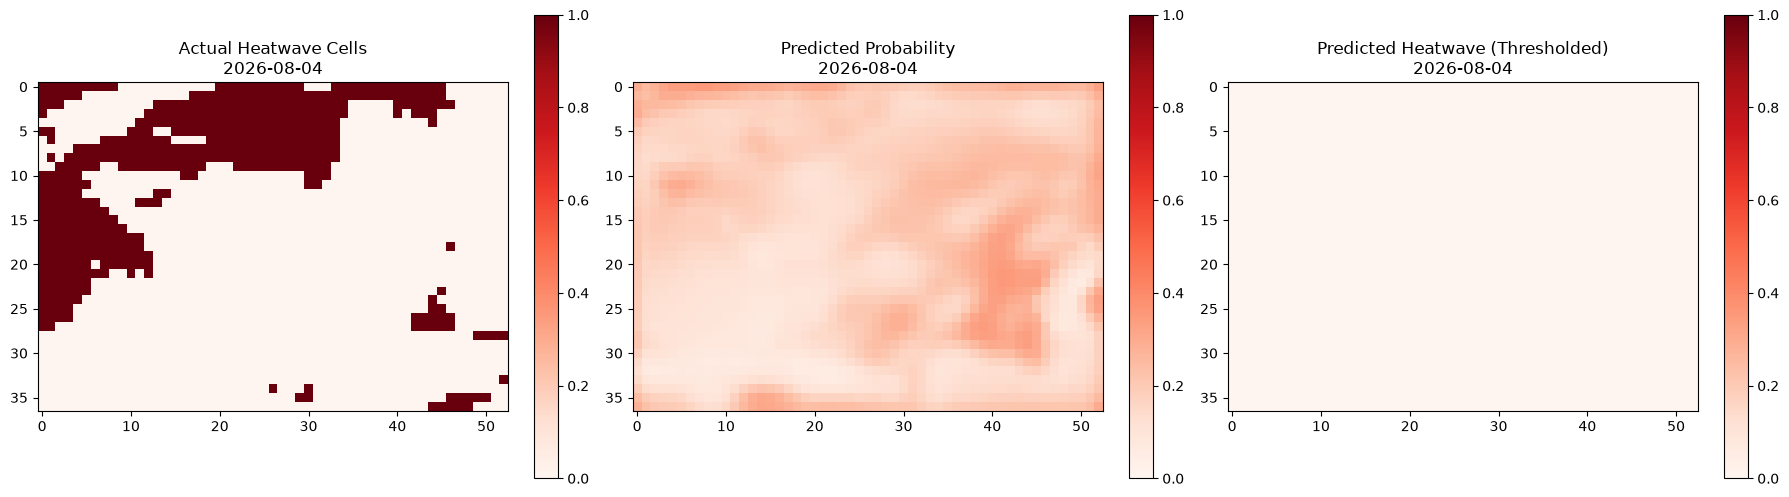

In [50]:
import matplotlib.pyplot as plt

# Find the index for August 4, 2026 specifically within your August subset
target_date = pd.Timestamp('2026-08-04')
target_idx_in_august = list(seq_dates[august_2026_mask]).index(target_date)
global_idx = august_indices[target_idx_in_august]

actual_map = y_test_seq[global_idx]
predicted_prob_map = test_probs[global_idx]
predicted_binary_map = (predicted_prob_map > best_threshold).astype(int)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Actual heatwave map
im0 = axes[0].imshow(actual_map, cmap='Reds', vmin=0, vmax=1)
axes[0].set_title(f"Actual Heatwave Cells\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im0, ax=axes[0], fraction=0.046)

# Predicted probability map (continuous, shows the model's underlying confidence)
im1 = axes[1].imshow(predicted_prob_map, cmap='Reds', vmin=0, vmax=1)
axes[1].set_title(f"Predicted Probability\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im1, ax=axes[1], fraction=0.046)

# Predicted binary map (after applying threshold)
im2 = axes[2].imshow(predicted_binary_map, cmap='Reds', vmin=0, vmax=1)
axes[2].set_title(f"Predicted Heatwave (Thresholded)\n{target_date.strftime('%Y-%m-%d')}")
plt.colorbar(im2, ax=axes[2], fraction=0.046)

plt.tight_layout()
plt.savefig('case_study_august4_2026.png', dpi=150)
plt.show()

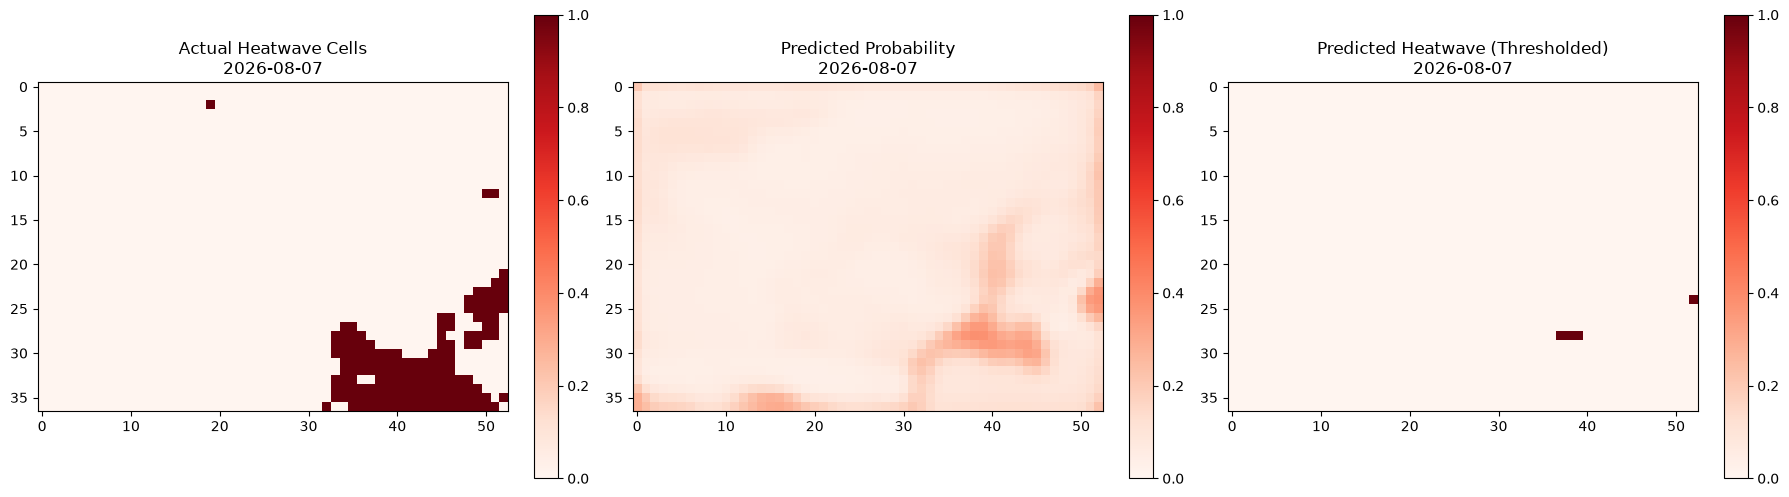

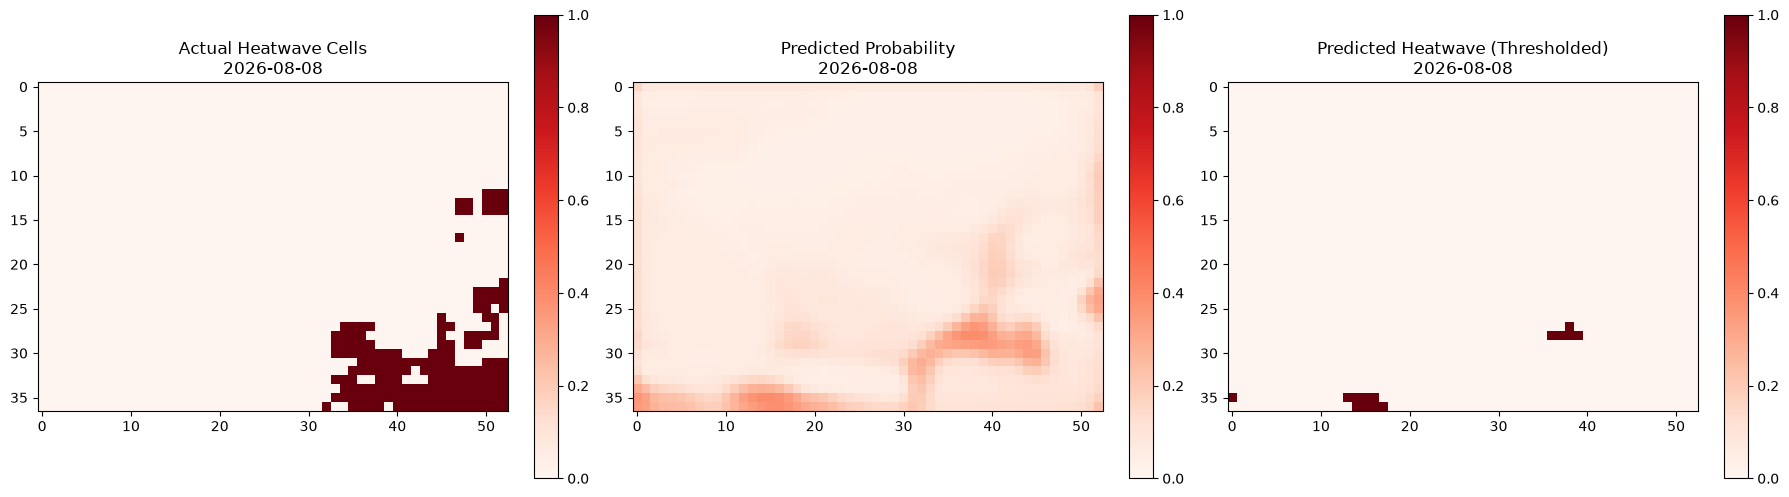

In [51]:
import matplotlib.pyplot as plt

def plot_case_study_day(target_date_str):
    target_date = pd.Timestamp(target_date_str)
    target_idx_in_august = list(seq_dates[august_2026_mask]).index(target_date)
    global_idx = august_indices[target_idx_in_august]

    actual_map = y_test_seq[global_idx]
    predicted_prob_map = test_probs[global_idx]
    predicted_binary_map = (predicted_prob_map > best_threshold).astype(int)

    fig, axes = plt.subplots(1, 3, figsize=(18, 5))

    im0 = axes[0].imshow(actual_map, cmap='Reds', vmin=0, vmax=1)
    axes[0].set_title(f"Actual Heatwave Cells\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im0, ax=axes[0], fraction=0.046)

    im1 = axes[1].imshow(predicted_prob_map, cmap='Reds', vmin=0, vmax=1)
    axes[1].set_title(f"Predicted Probability\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im1, ax=axes[1], fraction=0.046)

    im2 = axes[2].imshow(predicted_binary_map, cmap='Reds', vmin=0, vmax=1)
    axes[2].set_title(f"Predicted Heatwave (Thresholded)\n{target_date.strftime('%Y-%m-%d')}")
    plt.colorbar(im2, ax=axes[2], fraction=0.046)

    plt.tight_layout()
    plt.savefig(f'case_study_{target_date.strftime("%Y%m%d")}.png', dpi=150)
    plt.show()

plot_case_study_day('2026-08-07')
plot_case_study_day('2026-08-08')

In [52]:
# Create a version of the feature stack WITHOUT soil moisture (channel index 2)
X_train_ablation = X_train_norm[:, [0, 1], :, :]  # keep only temperature (0) and pressure (1)
X_val_ablation = X_val_norm[:, [0, 1], :, :]
X_test_ablation = X_test_norm[:, [0, 1], :, :]

# Rebuild sequences with the reduced feature set
X_train_seq_abl, y_train_seq_abl = create_spatial_sequences(X_train_ablation, y_train_grid, SEQ_LENGTH)
X_val_seq_abl, y_val_seq_abl = create_spatial_sequences(X_val_ablation, y_val_grid, SEQ_LENGTH)
X_test_seq_abl, y_test_seq_abl = create_spatial_sequences(X_test_ablation, y_test_grid, SEQ_LENGTH)

print("Ablation train shape:", X_train_seq_abl.shape)  # should show 2 channels instead of 3

Ablation train shape: (360, 7, 2, 37, 53)


In [53]:
# Convert to tensors
X_train_abl_t = torch.tensor(X_train_seq_abl, dtype=torch.float32)
y_train_abl_t = torch.tensor(y_train_seq_abl, dtype=torch.float32)
X_val_abl_t = torch.tensor(X_val_seq_abl, dtype=torch.float32)
y_val_abl_t = torch.tensor(y_val_seq_abl, dtype=torch.float32)
X_test_abl_t = torch.tensor(X_test_seq_abl, dtype=torch.float32)
y_test_abl_t = torch.tensor(y_test_seq_abl, dtype=torch.float32)

train_dataset_abl = TensorDataset(X_train_abl_t, y_train_abl_t)
train_loader_abl = DataLoader(train_dataset_abl, batch_size=8, shuffle=True)

# Same class weighting approach
raw_ratio_abl = (1 - y_train_seq_abl.mean()) / y_train_seq_abl.mean()
pos_weight_abl = torch.tensor([raw_ratio_abl ** 0.5], dtype=torch.float32)

criterion_abl = nn.BCEWithLogitsLoss(pos_weight=pos_weight_abl)
model_abl = ConvLSTMHeatwave(input_dim=2, hidden_dim=16)  # input_dim=2 now, no soil moisture
optimizer_abl = optim.Adam(model_abl.parameters(), lr=0.0005, weight_decay=1e-4)

num_epochs = 20
best_val_loss_abl = float('inf')
best_model_state_abl = None

for epoch in range(num_epochs):
    model_abl.train()
    epoch_loss = 0
    for X_batch, y_batch in train_loader_abl:
        optimizer_abl.zero_grad()
        outputs = model_abl(X_batch)
        loss = criterion_abl(outputs, y_batch)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model_abl.parameters(), max_norm=1.0)
        optimizer_abl.step()
        epoch_loss += loss.item()

    avg_train_loss = epoch_loss / len(train_loader_abl)

    model_abl.eval()
    with torch.no_grad():
        val_outputs = model_abl(X_val_abl_t)
        val_loss = criterion_abl(val_outputs, y_val_abl_t).item()

    if val_loss < best_val_loss_abl:
        best_val_loss_abl = val_loss
        best_model_state_abl = model_abl.state_dict()

    print(f"Epoch {epoch+1}/{num_epochs} — Train Loss: {avg_train_loss:.4f}, Val Loss: {val_loss:.4f}")

model_abl.load_state_dict(best_model_state_abl)
print(f"\nBest validation loss (no soil moisture): {best_val_loss_abl:.4f}")

Epoch 1/20 — Train Loss: 0.7599, Val Loss: 0.5886
Epoch 2/20 — Train Loss: 0.5109, Val Loss: 0.4089
Epoch 3/20 — Train Loss: 0.4593, Val Loss: 0.3967
Epoch 4/20 — Train Loss: 0.4526, Val Loss: 0.3966
Epoch 5/20 — Train Loss: 0.4530, Val Loss: 0.3849
Epoch 6/20 — Train Loss: 0.4474, Val Loss: 0.3834
Epoch 7/20 — Train Loss: 0.4418, Val Loss: 0.3818
Epoch 8/20 — Train Loss: 0.4396, Val Loss: 0.3785
Epoch 9/20 — Train Loss: 0.4331, Val Loss: 0.3792
Epoch 10/20 — Train Loss: 0.4376, Val Loss: 0.3792
Epoch 11/20 — Train Loss: 0.4270, Val Loss: 0.3735
Epoch 12/20 — Train Loss: 0.4282, Val Loss: 0.3766
Epoch 13/20 — Train Loss: 0.4282, Val Loss: 0.3719
Epoch 14/20 — Train Loss: 0.4184, Val Loss: 0.3737
Epoch 15/20 — Train Loss: 0.4224, Val Loss: 0.3728
Epoch 16/20 — Train Loss: 0.4141, Val Loss: 0.3685
Epoch 17/20 — Train Loss: 0.4095, Val Loss: 0.3683
Epoch 18/20 — Train Loss: 0.4086, Val Loss: 0.3660
Epoch 19/20 — Train Loss: 0.4047, Val Loss: 0.3660
Epoch 20/20 — Train Loss: 0.3977, Val Lo

In [54]:
model_abl.eval()
with torch.no_grad():
    test_logits_abl = model_abl(X_test_abl_t)
    test_probs_abl = torch.sigmoid(test_logits_abl).numpy()

y_test_flat_abl = y_test_seq_abl.flatten()
test_probs_flat_abl = test_probs_abl.flatten()

# Find best threshold for this model (same approach as before)
precisions_abl, recalls_abl, thresholds_abl = precision_recall_curve(y_test_flat_abl, test_probs_flat_abl)
f1_scores_abl = 2 * (precisions_abl * recalls_abl) / (precisions_abl + recalls_abl + 1e-8)
best_idx_abl = np.argmax(f1_scores_abl)
best_threshold_abl = thresholds_abl[best_idx_abl] if best_idx_abl < len(thresholds_abl) else 0.5

test_preds_abl = (test_probs_flat_abl > best_threshold_abl).astype(int)

print(f"Ablation (no soil moisture) — Threshold: {best_threshold_abl:.3f}")
print("Accuracy:", accuracy_score(y_test_flat_abl, test_preds_abl))
print("F1:", f1_score(y_test_flat_abl, test_preds_abl))
print("AUC:", roc_auc_score(y_test_flat_abl, test_probs_flat_abl))

Ablation (no soil moisture) — Threshold: 0.351
Accuracy: 0.8626364798502302
F1: 0.4538687996445037
AUC: 0.8318533028462742


In [55]:
results_ablation = {
    "model": "ConvLSTM (no soil moisture - ablation)",
    "threshold": float(best_threshold_abl),
    "accuracy": float(accuracy_score(y_test_flat_abl, test_preds_abl)),
    "f1_score": float(f1_score(y_test_flat_abl, test_preds_abl)),
    "auc": float(roc_auc_score(y_test_flat_abl, test_probs_flat_abl)),
    "full_model_auc": 0.851,
    "full_model_f1": 0.488
}

with open('ablation_results.json', 'w') as f:
    json.dump(results_ablation, f, indent=4)

print("Ablation results saved.")

Ablation results saved.
